# PART 1

### Q1. Fomratting with an f-string

In [105]:
# difining variables
brand = "Alpha"
price = 249.90
units = 2

# calculating total
total = price * units

# printing using f-string
print(
    f"----------- \n{brand} \ntotal price: {total:.2f} for units: {units} \n-----------"
)

----------- 
Alpha 
total price: 499.80 for units: 2 
-----------


### Q2. WOrking with a list

In [106]:
# defining list
prices = [120, 180, 150, 200, 170]

# appending 190 to the list
prices.append(190)

# printing last two elements
print(prices[-2:])


[170, 190]


### Q3 A small function

In [107]:
# defining list
discounts = [3, 8, 6, 2, 18]

# function to count discounts greater than 5
def count_discounted(discounts):
  count = 0
  for d in discounts:
    if d > 5:
      count += 1
  print(f"The count of the discounts > 5 is: {count}")

count_discounted(discounts)

The count of the discounts > 5 is: 3


# PART 2

In [108]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Q1. Load csv and display the first 13 rows

In [109]:
# loading csv
df = pd.read_csv("./data/Mobiles.csv")

# display first 13 rows
df.head(13)

,Date,Brand,Model,Units_Sold,Price,Discount,Rating
0,2024-03-25,Apple,Model_4,66,851.32,10,3.5
1,2024-01-12,Samsung,Model_15,34,1086.33,10,4.8
2,2024-03-01,Samsung,Model_6,166,951.58,0,4.3
3,2024-02-10,Oppo,Model_15,45,408.50,10,4.4
4,2024-02-02,Oppo,Model_3,112,1112.21,0,4.5
5,2024-02-19,Oppo,Model_14,251,359.80,10,4.7
6,2024-03-08,Samsung,Model_20,40,780.57,0,4.0
7,2024-03-11,Xiaomi,Model_14,57,427.92,10,4.6
8,2024-03-26,OnePlus,Model_4,295,310.54,5,4.3
9,2024-02-02,Xiaomi,Model_12,176,679.83,10,4.7


### Q2. display each columns data type

In [110]:
# data types for each column and observation
print(df.dtypes, " \nobservation: the disk size of the data frame can be reduced by converting int64 data type columns to int32 data type")

Date              str
Brand             str
Model             str
Units_Sold      int64
Price         float64
Discount        int64
Rating        float64
dtype: object  
observation: the disk size of the data frame can be reduced by converting int64 data type columns to int32 data type


### Q3. Funtion

In [111]:
# creating function
def count_discounted(df):
    count = 0
    for d in df["Discount"]:
        if d > 5:
            count += 1
    print(f"the count of discounts > 5% is: {count}")


count_discounted(df)

the count of discounts > 5% is: 43


### Q4. average selling price by brand

In [112]:
df.groupby("Brand")["Price"].mean().sort_values(ascending=False)

Brand
Samsung    887.505000
Xiaomi     763.858182
OnePlus    731.494375
Apple      707.028333
Oppo       598.956538
Name: Price, dtype: float64

### Q5. Funtion

In [113]:
df

,Date,Brand,Model,Units_Sold,Price,Discount,Rating
0,2024-03-25,Apple,Model_4,66,851.32,10,3.5
1,2024-01-12,Samsung,Model_15,34,1086.33,10,4.8
2,2024-03-01,Samsung,Model_6,166,951.58,0,4.3
3,2024-02-10,Oppo,Model_15,45,408.50,10,4.4
4,2024-02-02,Oppo,Model_3,112,1112.21,0,4.5
...,...,...,...,...,...,...,...
95,2024-04-01,Apple,Model_15,285,475.16,10,3.6
96,2024-02-10,Oppo,Model_8,229,351.88,10,4.9
97,2024-02-05,Oppo,Model_12,70,608.20,5,4.7
98,2024-03-25,Apple,Model_12,137,543.22,5,3.7


In [114]:
# creating function
def top3_model(df):
    return df.groupby("Model")["Units_Sold"].sum().nlargest(3)


top3_model(df)

Model
Model_14    2478
Model_3     1367
Model_19    1305
Name: Units_Sold, dtype: int64

# PART 3

### Q1

In [115]:
df["Units_Sold"] = df["Units_Sold"].astype("float")
df["Discount"] = df["Discount"].astype("float")

df.describe(include="float")

,Units_Sold,Price,Discount,Rating
count,100.00000,100.000000,100.000000,100.000000
mean,162.96000,727.832600,5.500000,4.237000
std,80.25237,253.292953,4.351941,0.443962
min,20.00000,310.540000,0.000000,3.500000
25%,94.00000,556.630000,0.000000,3.800000
50%,165.50000,692.145000,5.000000,4.300000
75%,230.00000,920.480000,10.000000,4.600000
max,296.00000,1189.230000,10.000000,5.000000


### Q2


In [116]:
df["Revenue"] = df["Units_Sold"] * df["Price"]
df["Month"] = pd.to_datetime(df["Date"]).dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()
print(monthly_revenue)

Month
2024-01    2865133.73
2024-02    3635679.67
2024-03    4070684.74
2024-04    1195503.61
Freq: M, Name: Revenue, dtype: float64


### Q3

In [117]:
df.groupby("Brand")["Rating"].mean().nlargest(1)

Brand
Xiaomi    4.377273
Name: Rating, dtype: float64

### Q4

Text(0, 0.5, 'Total Revenue')

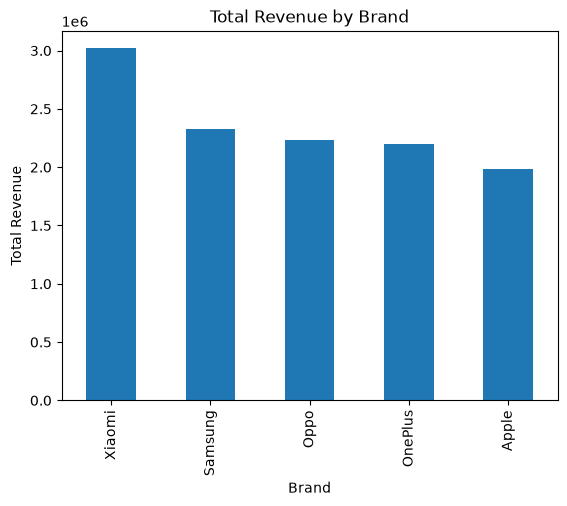

In [118]:
revenue_by_brand = df.groupby("Brand")["Revenue"].sum().sort_values(ascending=False)

ax = revenue_by_brand.plot(kind="bar", title="Total Revenue by Brand")
ax.set_xlabel("Brand")
ax.set_ylabel("Total Revenue")

# PART 4


### Q1

In [119]:
df

,Date,Brand,Model,Units_Sold,Price,Discount,Rating,Revenue,Month
0,2024-03-25,Apple,Model_4,66.0,851.32,10.0,3.5,56187.12,2024-03
1,2024-01-12,Samsung,Model_15,34.0,1086.33,10.0,4.8,36935.22,2024-01
2,2024-03-01,Samsung,Model_6,166.0,951.58,0.0,4.3,157962.28,2024-03
3,2024-02-10,Oppo,Model_15,45.0,408.50,10.0,4.4,18382.50,2024-02
4,2024-02-02,Oppo,Model_3,112.0,1112.21,0.0,4.5,124567.52,2024-02
...,...,...,...,...,...,...,...,...,...
95,2024-04-01,Apple,Model_15,285.0,475.16,10.0,3.6,135420.60,2024-04
96,2024-02-10,Oppo,Model_8,229.0,351.88,10.0,4.9,80580.52,2024-02
97,2024-02-05,Oppo,Model_12,70.0,608.20,5.0,4.7,42574.00,2024-02
98,2024-03-25,Apple,Model_12,137.0,543.22,5.0,3.7,74421.14,2024-03


Text(0, 0.5, 'Total Units Sold')

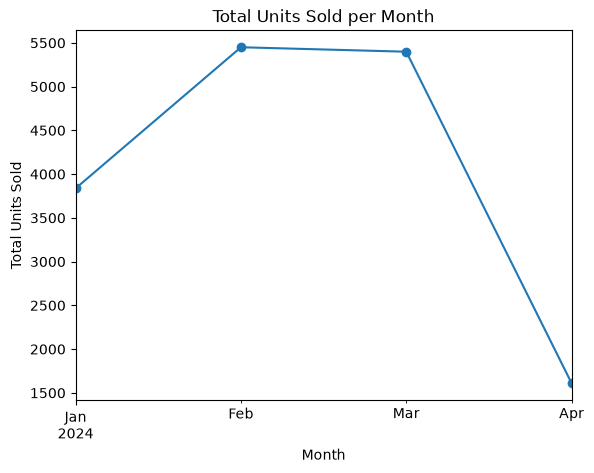

In [120]:
daily_units_sold = df.groupby((df["Month"]))["Units_Sold"].sum().sort_index()

ax = daily_units_sold.plot(kind="line", marker="o", title="Total Units Sold per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Total Units Sold")

### Q2

In [121]:
df1 = df.groupby("Brand")["Units_Sold"].sum()
df1

Brand
Apple      2825.0
OnePlus    3027.0
Oppo       3803.0
Samsung    2727.0
Xiaomi     3914.0
Name: Units_Sold, dtype: float64

(np.float64(-1.0999990177639576),
 np.float64(1.0999997615408643),
 np.float64(-1.099994310056247),
 np.float64(1.0999997290502974))

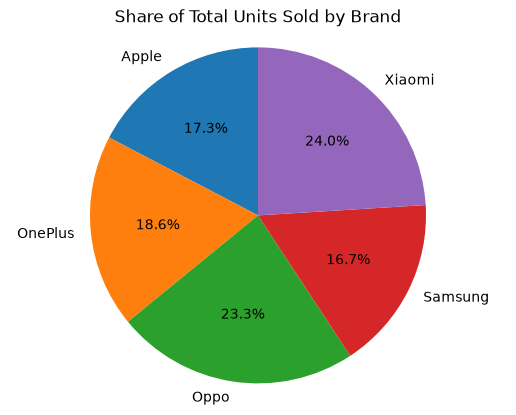

In [122]:
fig, ax = plt.subplots()

ax.pie(
  df1,
  labels=df1.index,
  autopct="%1.1f%%",
  startangle=90
)
ax.set_title("Share of Total Units Sold by Brand")
ax.axis("equal")

### Q3

In [123]:
print(
  "Xiaomi generated the highest total revenue, while Apple generated the lowest. \nXiaomi also sold the most units, with Oppo close behind. \nSamsung sold the fewest \nunits, although its revenue was higher than Apple's. \nOverall, units sold and revenue do not align perfectly, likely because average prices vary by brand."
)

Xiaomi generated the highest total revenue, while Apple generated the lowest. 
Xiaomi also sold the most units, with Oppo close behind. 
Samsung sold the fewest 
units, although its revenue was higher than Apple's. 
Overall, units sold and revenue do not align perfectly, likely because average prices vary by brand.
